# Exploratory Data Analysis (EDA)
## HR Analytics — Employee Attrition & Performance

### Objective
Analyze employee data to identify patterns and factors associated with employee attrition.

### Dataset
The cleaned HR dataset contains employee demographics, job roles, monthly income, job satisfaction, overtime, performance ratings, and attrition information.

### EDA Workflow
1. Load the cleaned dataset.
2. Inspect the dataset structure and statistical summary.
3. Analyze employee attrition distribution.
4. Explore attrition by department and job role.
5. Analyze the relationship between attrition, income, age, and years at the company.
6. Investigate the relationship between attrition, overtime, and job satisfaction.
7. Visualize key findings.
8. Summarize business insights.

### Expected Outcome
Identify workforce patterns associated with employee attrition and develop data-driven recommendations for HR decision-making.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/hr_analytics_clean.csv")

print(df.shape)
df.head()

(1500, 12)


,EmployeeID,Age,Gender,Department,JobRole,MonthlyIncome,YearsAtCompany,JobSatisfaction,Attrition,Overtime,PerformanceRating,EducationLevel
0,EMP00739,42.0,Female,Customer Support,Support Agent,34364.0,22.0,Medium,No,No,Needs Improvement,PhD
1,EMP00360,23.0,Female,IT,IT Support,40000.0,5.0,Medium,No,No,Exceeds Expectations,High School
2,EMP00807,52.0,Female,Operations,Operations Analyst,28302.0,27.0,Very High,No,Yes,Needs Improvement,Bachelor's
3,EMP00596,39.0,Male,Customer Support,Support Agent,11010.0,10.0,High,No,Yes,Needs Improvement,Master's
4,EMP00228,29.0,Male,Research & Development,Research Scientist,15678.0,7.0,Medium,No,No,Exceeds Expectations,PhD


### Observation

The cleaned HR Analytics dataset was successfully loaded into a Pandas DataFrame. The `df.shape` function displays the number of rows and columns, while `df.head()` displays the first five records. These steps help verify that the dataset has been loaded correctly and provide an initial understanding of its structure and employee information.


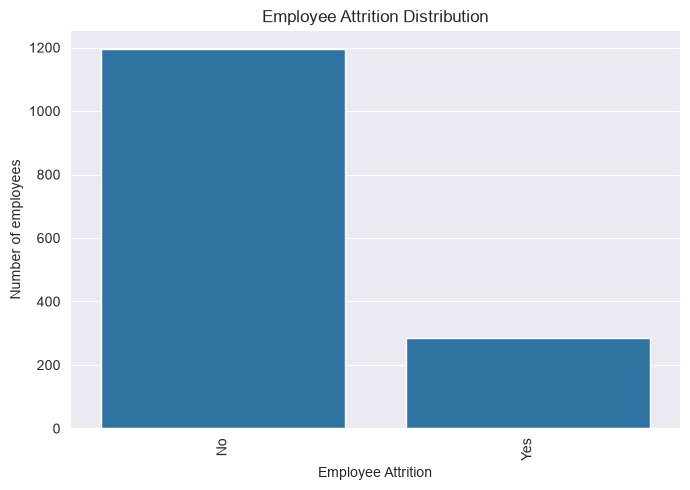

In [3]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
attrition_counts=df["Attrition"].dropna().value_counts()
plt.figure(figsize=(7,5))
sns.barplot(x=attrition_counts.index,
            y=attrition_counts.values)
plt.title("Employee Attrition Distribution")
plt.xlabel("Employee Attrition")
plt.ylabel("Number of employees")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Observation

The bar chart displays the distribution of employees based on their attrition status. It compares the number of employees who stayed with the company (`No`) against those who left (`Yes`). The chart shows that more employees stayed than left, indicating that most employees in the dataset continued working for the company. This analysis provides an overview of the company's employee retention pattern.


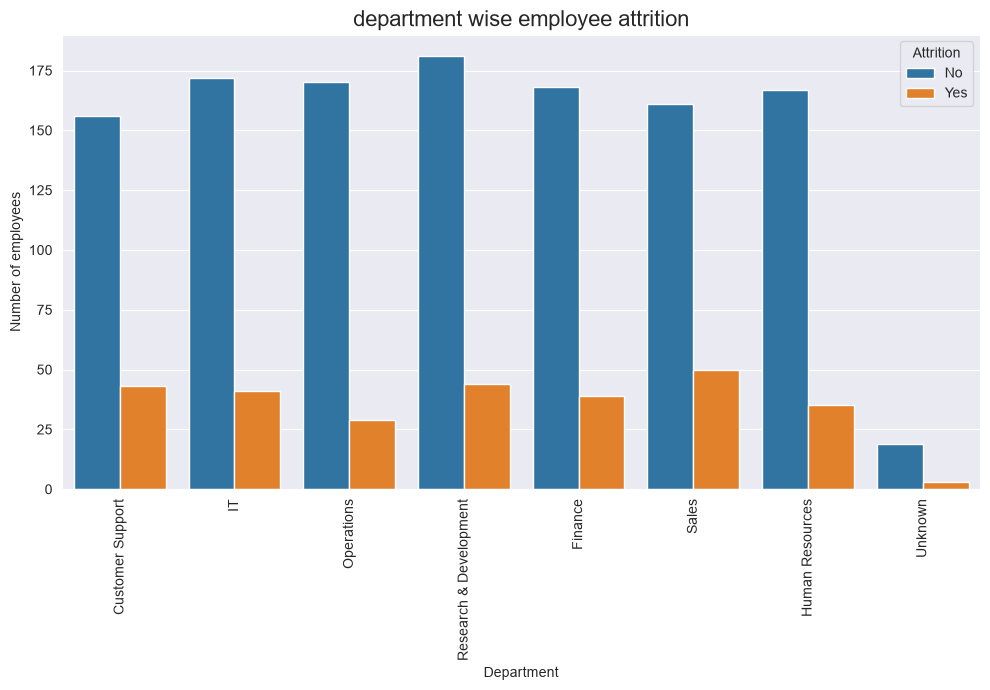

In [4]:
plt.figure(figsize=(10,7))

sns.countplot(data=df,
              x="Department",
              hue="Attrition",
              )
plt.title("department wise employee attrition",fontsize=16)
plt.xlabel("Department",fontsize=10)
plt.ylabel("Number of employees",fontsize=10)
plt.xticks(rotation=90)
plt.legend(title="Attrition")
plt.tight_layout()
plt.show()

### Observation

The count plot compares the numbers of employees who stayed and left across different departments. It shows the distribution of attrition within each department and helps identify departments with a higher number of employee departures. However, these counts depend on department size, so they should not be used alone to compare attrition risk. Calculating the attrition rate for each department provides a more meaningful comparison.


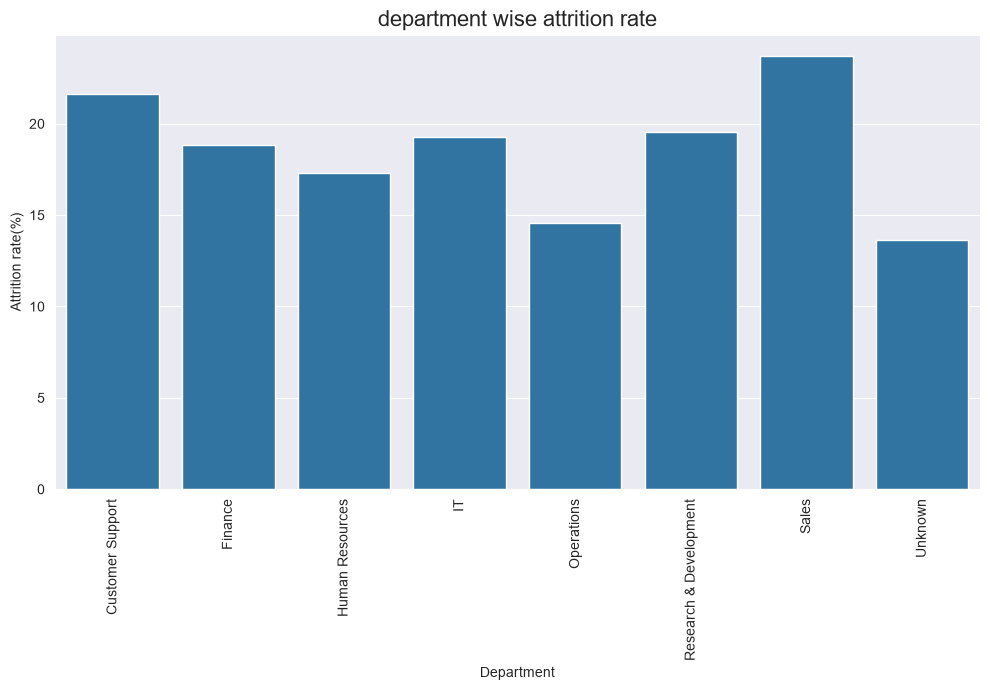

In [5]:
attrition_rate=df.dropna(subset=["Attrition"]).groupby("Department")["Attrition"].apply(lambda x: (x=="Yes").mean()*100)
plt.figure(figsize=(10,7))
sns.barplot(x=attrition_rate.index,
            y=attrition_rate.values)
plt.title("department wise attrition rate",fontsize=16)
plt.xlabel("Department")
plt.ylabel("Attrition rate(%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

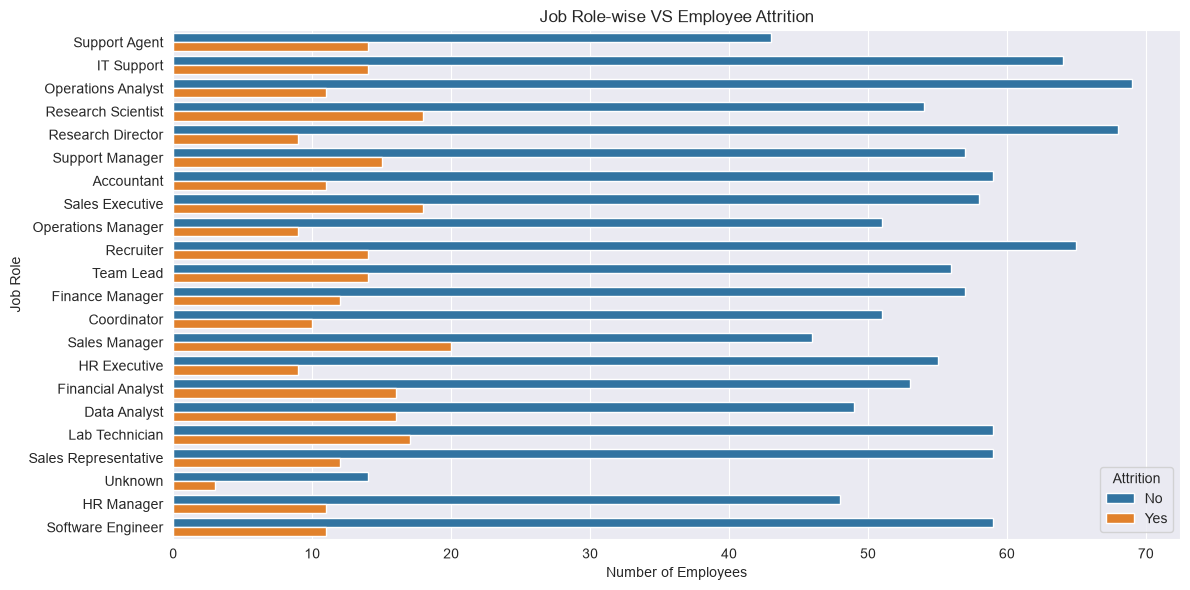

In [6]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df.dropna(subset=["Attrition"]),
    y="JobRole",
    hue="Attrition"
)

plt.title("Job Role-wise VS Employee Attrition")
plt.xlabel("Number of Employees")
plt.ylabel("Job Role")
plt.legend(title="Attrition")
plt.tight_layout()
plt.show()

### Observation

The count plot compares the numbers of employees who stayed and left across different job roles. It helps identify job roles with higher numbers of employee departures and compare retention patterns across roles. However, the number of departures alone does not indicate the likelihood of an employee leaving, because the total number of employees varies across job roles. Therefore, job role-wise attrition rates should also be examined for a fair comparison.


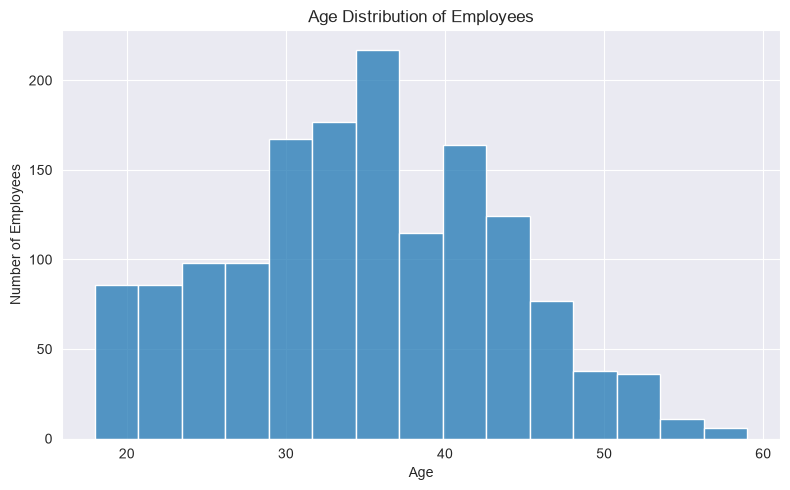

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=15)

plt.title("Age Distribution of Employees")
plt.xlabel("Age")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

### Observation

The histogram shows the distribution of employees across different age groups. It helps identify the age ranges in which most employees fall and understand the overall age profile of the workforce. This analysis provides a general overview of employee demographics and serves as a starting point for investigating the relationship between age and employee attrition.


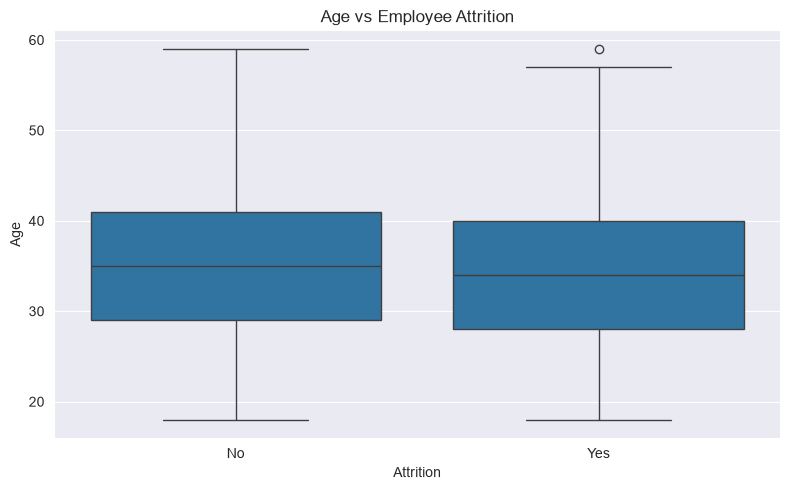

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df.dropna(subset=["Attrition"]),
    x="Attrition",
    y="Age"
)

plt.title("Age vs Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Age")

plt.tight_layout()
plt.show()

### Observation

The box plot compares the age distributions of employees who stayed with the company and those who left. The median lines show the typical age in each group, while the boxes represent the middle 50% of employee ages. The whiskers show the broader age distribution, and any points beyond them may indicate potential outliers.

This visualization helps identify differences in age distribution between employees who stayed and those who left. It provides an initial understanding of the relationship between employee age and attrition.


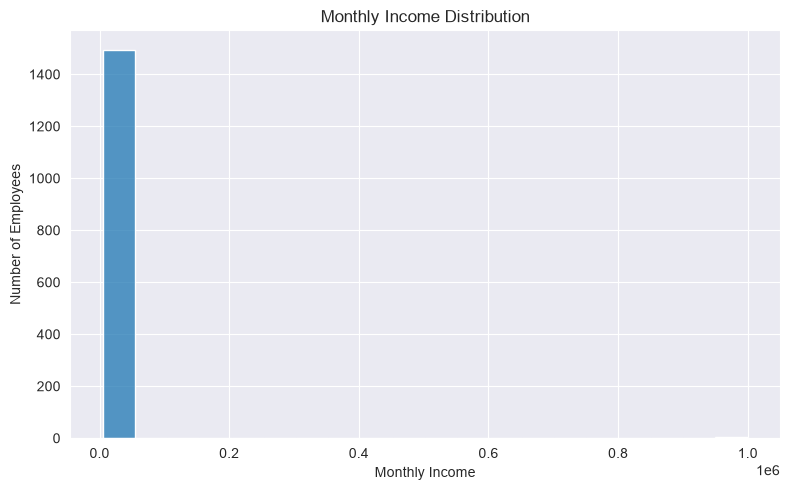

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="MonthlyIncome", bins=20)

plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

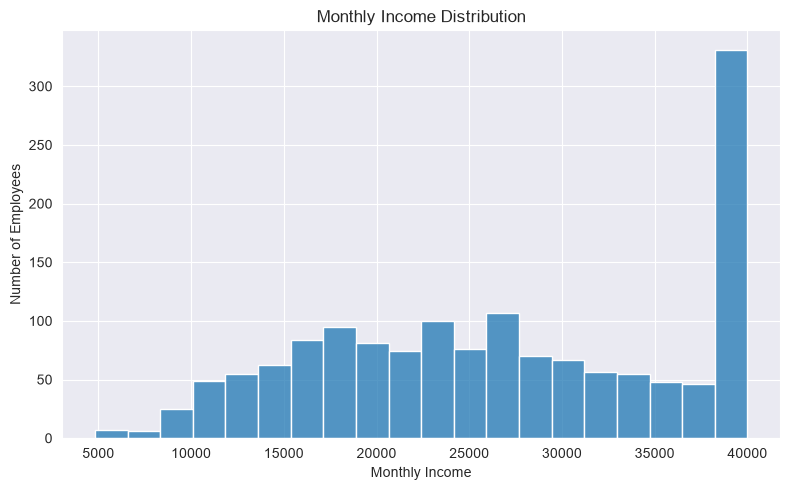

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df[df["MonthlyIncome"] < 100000],
             x="MonthlyIncome", bins=20)

plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

### Observation

The histogram shows the distribution of employee monthly incomes, considering only records with a monthly income below 100,000. The x-axis represents monthly income, while the y-axis represents the number of employees within each income range. This visualization helps identify the income ranges in which employees are concentrated and understand the overall salary distribution. Values of 100,000 or above are excluded from this graph, so the results represent only the filtered records.


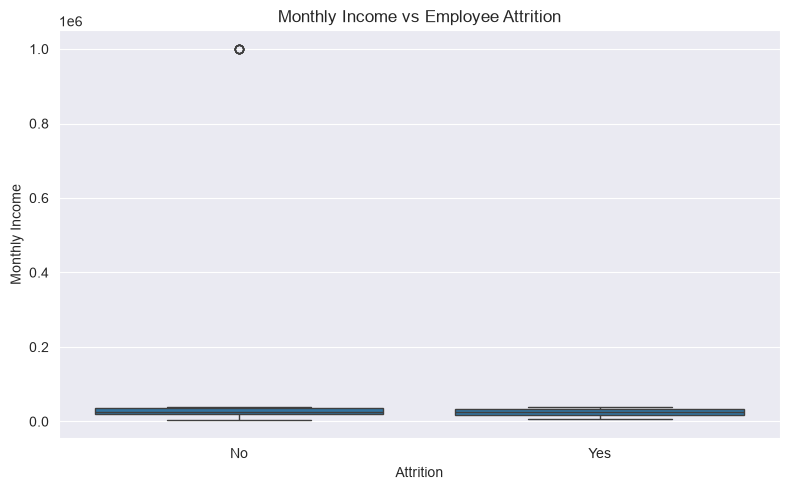

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df.dropna(subset=["Attrition"]),
    x="Attrition",
    y="MonthlyIncome"
)

plt.title("Monthly Income vs Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.tight_layout()
plt.show()


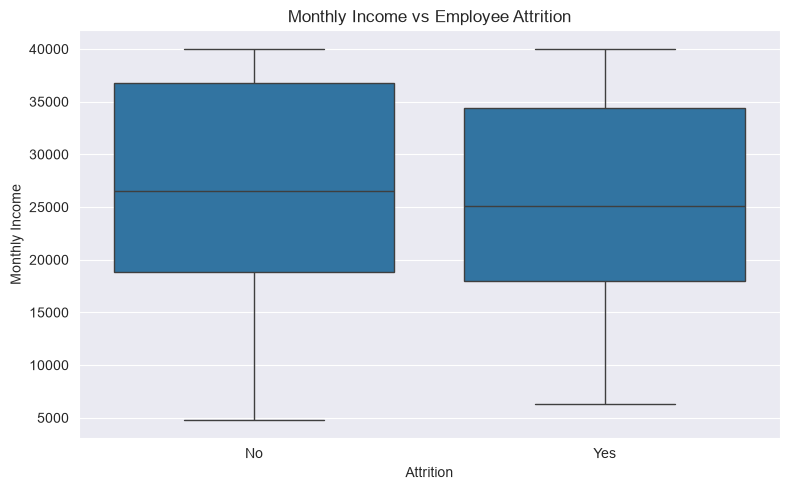

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df[df["MonthlyIncome"] < 100000],
            x="Attrition", y="MonthlyIncome")

plt.title("Monthly Income vs Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.tight_layout()
plt.show()

### Observation

The box plot compares the monthly income distributions of employees who stayed with the company and those who left, considering only records with a monthly income below 100,000. The median line represents the middle income in each group, while the box shows the middle 50% of income values. The whiskers indicate the spread of the data, and points beyond them may represent potential outliers.

This visualization helps compare income patterns between the two attrition groups while reducing the influence of extremely high income values. However, filtering changes the dataset being analyzed, so the excluded records should be investigated before drawing final conclusions.


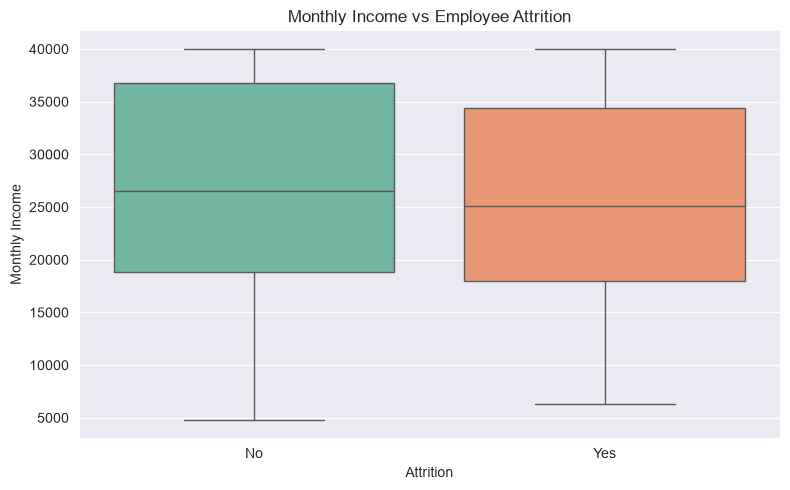

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df[df["MonthlyIncome"] < 100000],
    x="Attrition",
    y="MonthlyIncome",
    hue="Attrition",
    palette="Set2",
    legend=False
)

plt.title("Monthly Income vs Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.tight_layout()
plt.show()

### Observation

The box plot compares the monthly income distributions of employees who stayed with the company and those who left, considering only records with monthly income below 100,000. The median line in each box represents the median income, while the box shows the middle 50% of income values. The whiskers indicate the spread of the data, and any points beyond them may represent potential outliers.

The visualization helps identify differences in income distributions between the two attrition groups. However, the graph alone cannot establish whether income influences an employee's decision to leave. The excluded income values should also be investigated before drawing final conclusions.


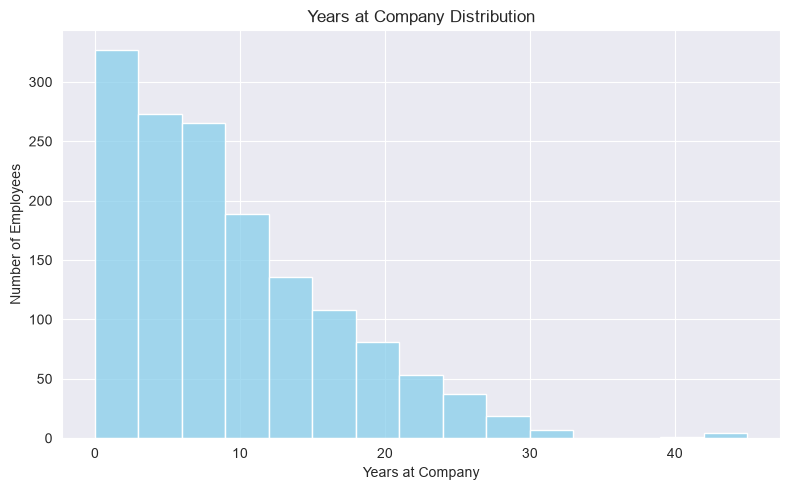

In [14]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x="YearsAtCompany", bins=15, color="skyblue")

plt.title("Years at Company Distribution")
plt.xlabel("Years at Company")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

### Observation

The histogram shows the distribution of employees based on the number of years they have worked at the company.

* **X-axis:** Years employees have worked at the company.
* **Y-axis:** Number of employees.
* **Bars:** Each bar represents the number of employees within a range of years of service. The `bins=15` parameter divides the data into 15 intervals.

This visualization helps identify whether the company has more new employees or employees with longer service periods. It also shows how employee tenure is distributed across the organization.

**Conclusion:** The histogram helps us understand employee tenure patterns. However, this graph alone cannot determine whether years at the company influence employee attrition; we need to compare tenure with attrition status to investigate that relationship.


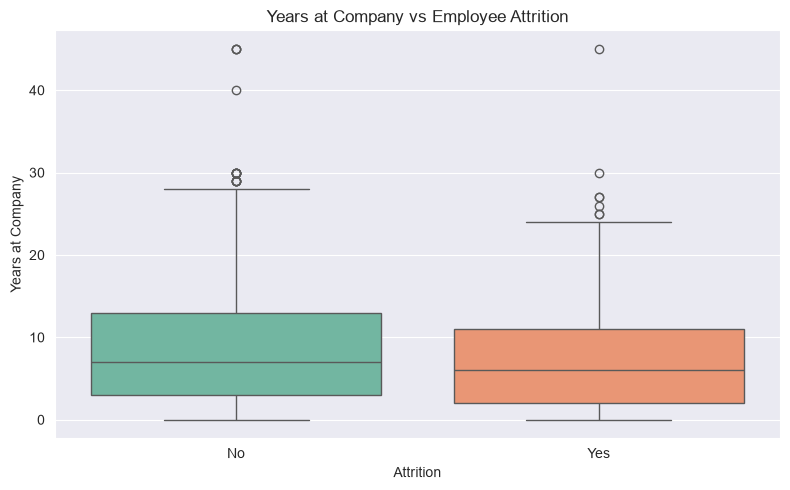

In [15]:
plt.figure(figsize=(8,5))
sns.boxplot(
            data=df,
            x="Attrition",
            y="YearsAtCompany",
            hue="Attrition",
            palette="Set2",
            legend=False
            )
plt.title("Years at Company vs Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")
plt.tight_layout()
plt.show()

### Observation

The box plot compares the number of years employees have worked at the company with their attrition status.

* **X-axis:** Attrition status — Yes (employees who left) and No (employees who stayed).
* **Y-axis:** Number of years employees have worked at the company.
* **Middle line inside each box:** Median years of service.
* **Box:** Represents the middle 50% of the values.
* **Whiskers and points:** Show the spread of the data and potential outliers.

By comparing the two boxes, we can identify whether employees who left generally had shorter or longer service periods than employees who stayed.

**Conclusion:** This graph helps investigate the relationship between employee tenure and attrition. If the median tenure is lower for employees who left, it may suggest that employees with shorter service periods are more likely to leave. However, the actual conclusion must be based on the displayed box plot, and the graph alone does not prove causation.


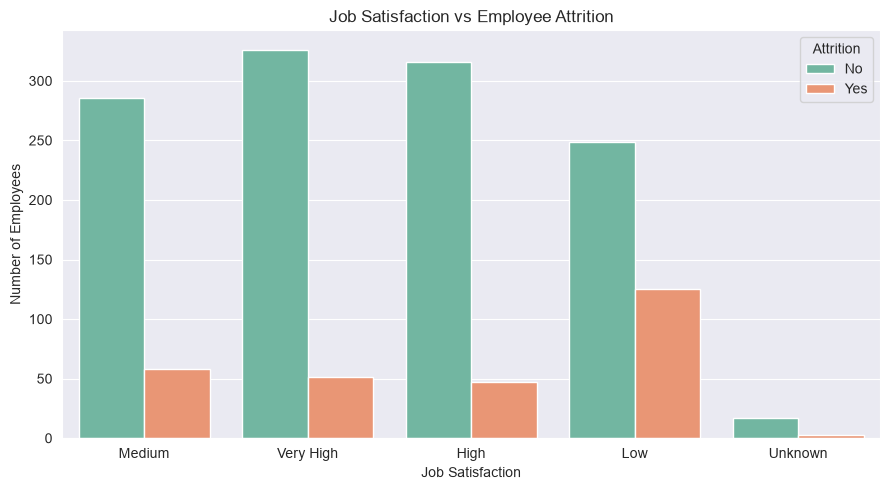

In [16]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df.dropna(subset=["Attrition"]),
    x="JobSatisfaction",
    hue="Attrition",
    palette="Set2"
)

plt.title("Job Satisfaction vs Employee Attrition")
plt.xlabel("Job Satisfaction")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

### Observation

The count plot compares employee job satisfaction levels with their attrition status. It helps us understand how many employees stayed with the company and how many left at each satisfaction level.

* **X-axis:** Job satisfaction levels — Low, Medium, High, and Very High.
* **Y-axis:** Number of employees.
* **Different colors:** Represent employees who stayed (`No`) and employees who left (`Yes`).
* **`dropna(subset=["Attrition"])`:** Excludes records where the attrition status is missing.

**Output interpretation:** The chart shows the number of employees who stayed and left within each satisfaction category. In the dataset, the Low satisfaction group has 125 employees who left, compared with 47 in the High group, 58 in the Medium group, and 51 in the Very High group.

**Conclusion:** Low job satisfaction is associated with a higher number of employee departures in this dataset. However, these are counts, not attrition rates. Comparing the percentage of employees who left within each satisfaction category would provide a fairer comparison because the group sizes differ.


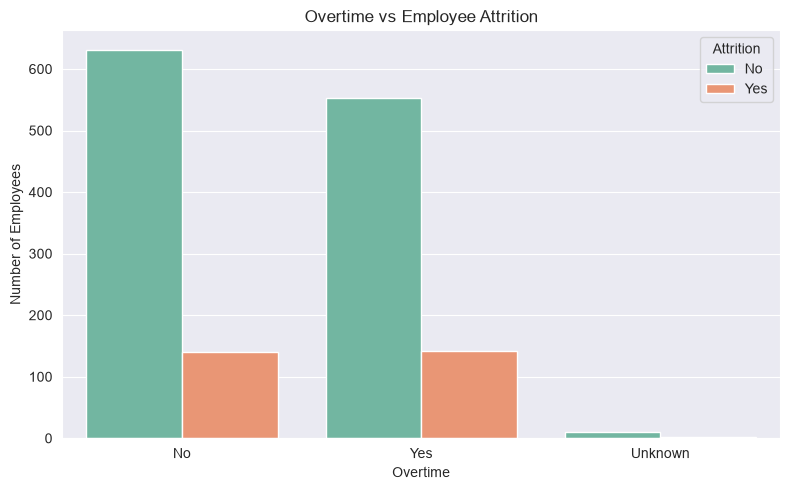

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df.dropna(subset=["Attrition"]),
    x="Overtime",
    hue="Attrition",
    palette="Set2"
)

plt.title("Overtime vs Employee Attrition")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

### Observation

The count plot compares employee overtime status with their attrition status. It helps us understand how many employees stayed with the company and how many left, based on whether they work overtime.

* **X-axis:** Overtime status — Yes, No, and any other recorded category.
* **Y-axis:** Number of employees.
* **Different colors:** Represent employees who stayed (`No`) and employees who left (`Yes`).
* **`dropna(subset=["Attrition"])`:** Excludes records with missing attrition status.

**Output interpretation:** In the dataset, 142 employees who worked overtime left the company, while 553 stayed. Among employees who did not work overtime, 140 left and 631 stayed.

**Conclusion:** The dataset shows more departures among employees who worked overtime, but the group sizes are different. The attrition rate is approximately **20.43% for employees who worked overtime** and **18.16% for those who did not**. This suggests a modest association between overtime and attrition, but it does not prove that overtime causes employees to leave.


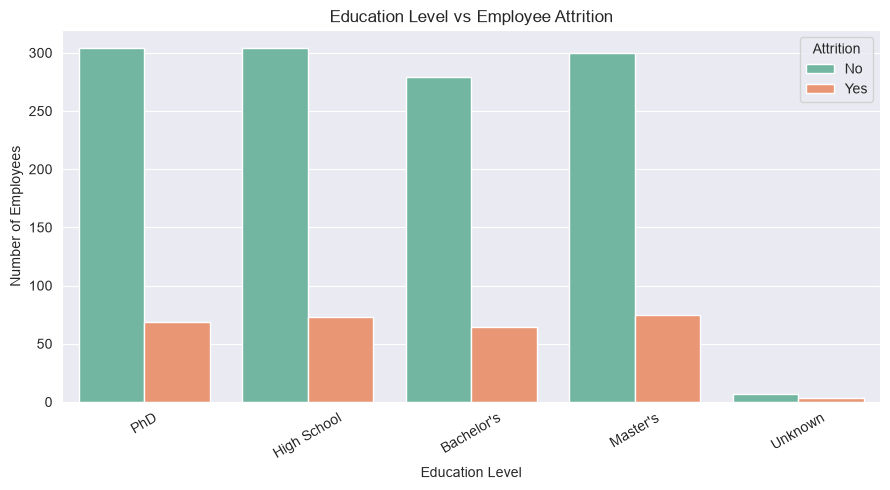

In [18]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df.dropna(subset=["Attrition"]),
    x="EducationLevel",
    hue="Attrition",
    palette="Set2"
)

plt.title("Education Level vs Employee Attrition")
plt.xlabel("Education Level")
plt.ylabel("Number of Employees")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Observation

The count plot compares employee education levels with attrition status. The X-axis represents education levels, and the Y-axis shows the number of employees. Different colors indicate employees who stayed and those who left.

**Conclusion:** The chart helps identify attrition patterns across education levels. However, attrition rates should be compared to determine which group has a higher likelihood of leaving.


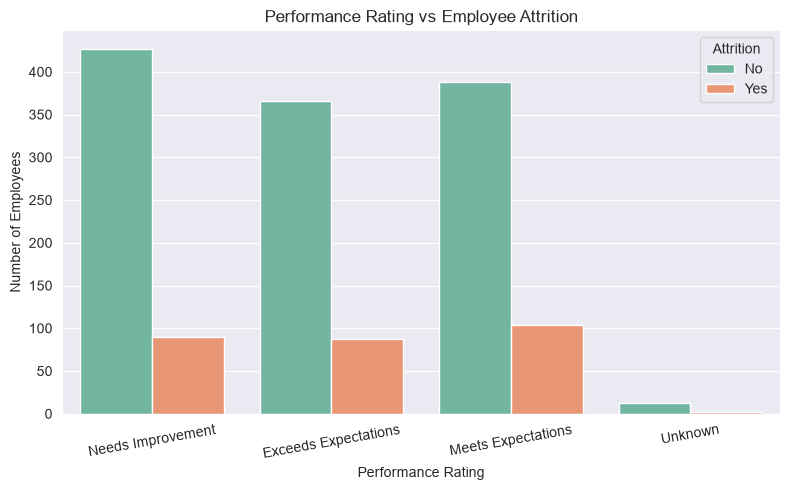

In [19]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df.dropna(subset=["Attrition"]),
              x="PerformanceRating",
              hue="Attrition",
              palette="Set2"
              )
plt.title("Performance Rating vs Employee Attrition")
plt.xlabel("Performance Rating")
plt.ylabel("Number of Employees")

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

### Observation

The count plot compares employee performance ratings with attrition status. The X-axis shows performance ratings, and the Y-axis shows the number of employees. Different colors represent employees who stayed and those who left.

**Conclusion:** The chart helps identify attrition patterns across performance ratings. Comparing attrition rates for each rating gives a clearer picture than comparing counts alone.


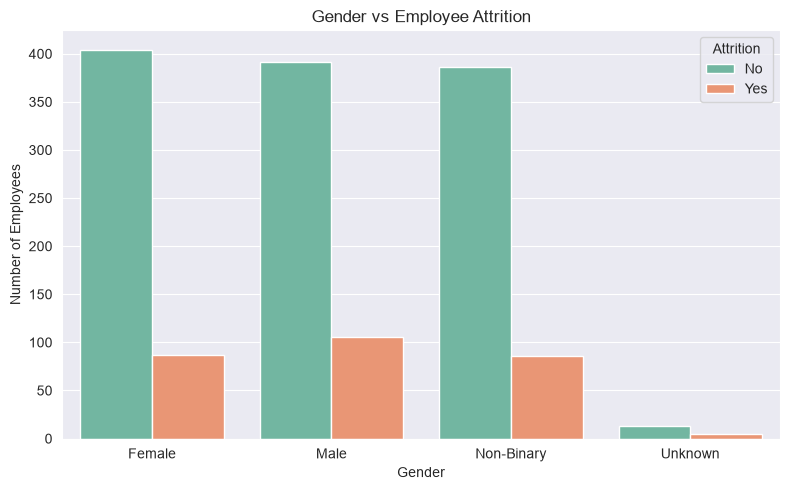

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df.dropna(subset=["Attrition"]),
    x="Gender",
    hue="Attrition",
    palette="Set2"
)

plt.title("Gender vs Employee Attrition")
plt.xlabel("Gender")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

### Observation

The count plot compares employee gender with attrition status. The X-axis shows gender, and the Y-axis represents the number of employees. Different colors indicate employees who stayed and those who left.

**Conclusion:** The chart helps compare attrition patterns across gender categories. However, attrition rates should be compared rather than counts alone, and gender should not be assumed to cause employee attrition.


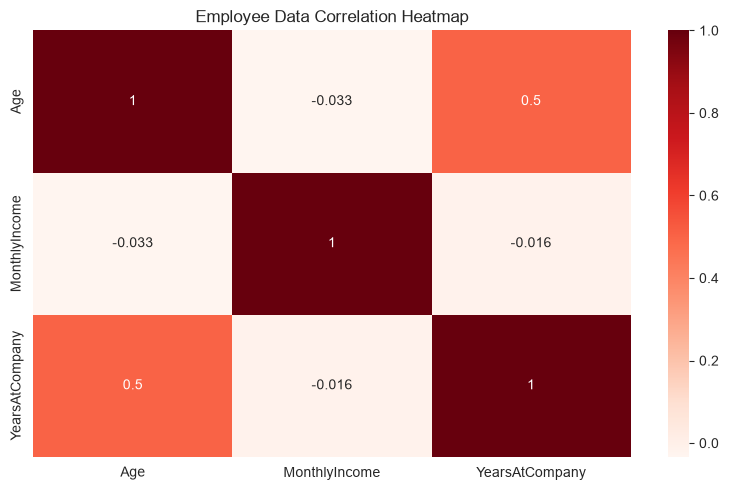

In [21]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df[["Age", "MonthlyIncome", "YearsAtCompany"]].corr(),
    annot=True,
    cmap="Reds"
)

plt.title("Employee Data Correlation Heatmap")
plt.tight_layout()
plt.show()

### Observation

The heatmap shows the correlation between Age, Monthly Income, and Years at Company. Values range from **-1 to +1**: positive values indicate a positive relationship, negative values indicate a negative relationship, and values near 0 indicate a weak linear relationship. The diagonal values are always 1 because each variable is perfectly correlated with itself.

**Conclusion:** The heatmap helps identify relationships between employee age, income, and tenure. Stronger relationships appear as values closer to -1 or +1.


In [22]:
print("1. ATTRITION COUNT")
print(df["Attrition"].value_counts())

print("\n2. DEPARTMENT-WISE ATTRITION RATE")
print(
    df.dropna(subset=["Attrition"])
    .groupby("Department")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

print("\n3. OVERTIME VS ATTRITION")
print(pd.crosstab(df["Overtime"], df["Attrition"]))

print("\n4. JOB SATISFACTION VS ATTRITION")
print(pd.crosstab(df["JobSatisfaction"], df["Attrition"]))

print("\n5. GENDER VS ATTRITION")
print(pd.crosstab(df["Gender"], df["Attrition"]))

1. ATTRITION COUNT
Attrition
No     1194
Yes     284
Name: count, dtype: int64

2. DEPARTMENT-WISE ATTRITION RATE
Department
Customer Support          21.61
Finance                   18.84
Human Resources           17.33
IT                        19.25
Operations                14.57
Research & Development    19.56
Sales                     23.70
Unknown                   13.64
Name: Attrition, dtype: float64

3. OVERTIME VS ATTRITION
Attrition   No  Yes
Overtime           
No         631  140
Unknown     10    2
Yes        553  142

4. JOB SATISFACTION VS ATTRITION
Attrition         No  Yes
JobSatisfaction          
High             316   47
Low              249  125
Medium           286   58
Unknown           17    3
Very High        326   51

5. GENDER VS ATTRITION
Attrition    No  Yes
Gender              
Female      404   87
Male        391  106
Non-Binary  386   86
Unknown      13    5


In [23]:
job_role_attrition = (
    df[df["Attrition"].isin(["Yes", "No"])]
    .groupby("JobRole")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("JOB ROLE-WISE ATTRITION RATE")
print(job_role_attrition.round(2))

JOB ROLE-WISE ATTRITION RATE
JobRole
Sales Manager           30.30
Research Scientist      25.00
Data Analyst            24.62
Support Agent           24.56
Sales Executive         23.68
Financial Analyst       23.19
Lab Technician          22.37
Support Manager         20.83
Team Lead               20.00
HR Manager              18.64
IT Support              17.95
Recruiter               17.72
Unknown                 17.65
Finance Manager         17.39
Sales Representative    16.90
Coordinator             16.39
Software Engineer       15.71
Accountant              15.71
Operations Manager      15.00
HR Executive            14.06
Operations Analyst      13.75
Research Director       11.69
Name: Attrition, dtype: float64


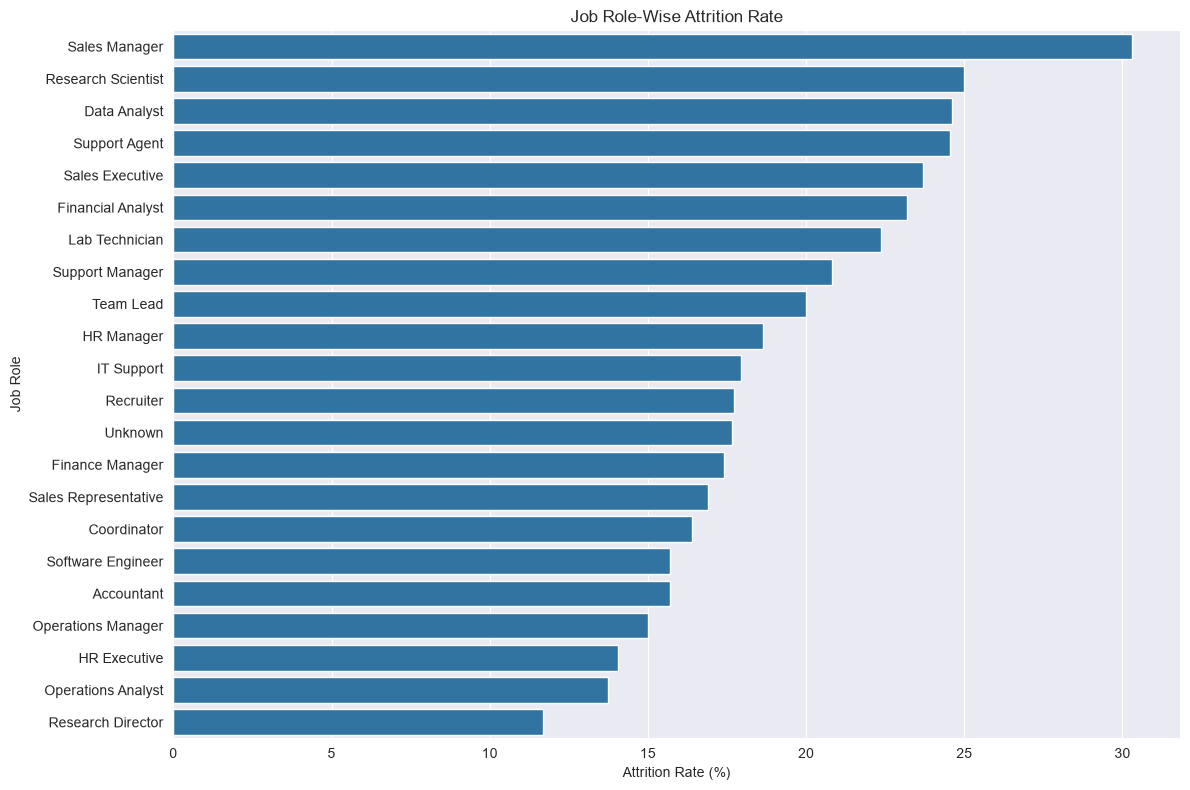

In [24]:
plt.figure(figsize=(12, 8))

sns.barplot(
    x=job_role_attrition.values,
    y=job_role_attrition.index
)

plt.title("Job Role-Wise Attrition Rate")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")
plt.tight_layout()
plt.show()

### Job Role-Wise Attrition Analysis

The analysis shows differences in employee attrition rates across job roles. Sales Managers have the highest observed attrition rate at 30.30%, followed by Research Scientists at 25.00%. Research Directors have the lowest rate among the identified job roles at 11.69%.

These findings suggest that HR should investigate the factors associated with higher attrition in these roles. However, the results show associations rather than causes, and the number of employees in each role should be considered when interpreting the percentages.


In [25]:
df_valid = df[df["Attrition"].isin(["Yes", "No"])].copy()

df_valid["AgeGroup"] = pd.cut(
    df_valid["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["Under 25", "25–34", "35–44", "45–54", "55+"],
    right=False
)

age_attrition = (
    df_valid.groupby("AgeGroup", observed=False)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print("AGE-GROUP-WISE ATTRITION RATE")
print(age_attrition.round(2))

AGE-GROUP-WISE ATTRITION RATE
AgeGroup
Under 25    25.89
25–34       19.28
35–44       18.09
45–54       15.34
55+         21.43
Name: Attrition, dtype: float64


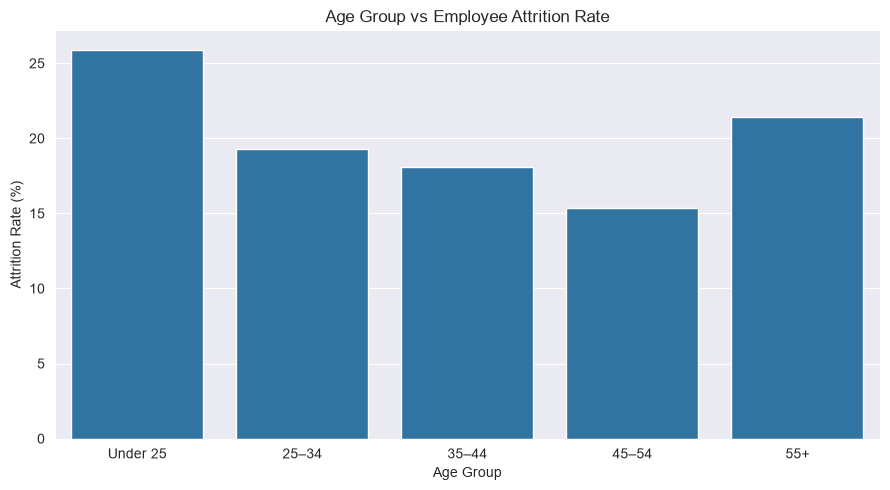

In [26]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=age_attrition.index,
    y=age_attrition.values
)

plt.title("Age Group vs Employee Attrition Rate")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

### Age Group-Wise Attrition Analysis

The analysis reveals differences in attrition rates across age groups. Employees under 25 have the highest observed attrition rate at 25.89%, while employees aged 45–54 have the lowest rate at 15.34%. The rate increases to 21.43% among employees aged 55 and above.

These findings suggest that employee retention patterns vary by age group. HR could investigate the career expectations, development opportunities, and retention needs of different age groups. However, these results alone do not establish the reasons for employee departures.


In [27]:
df.isnull().sum()

EmployeeID            0
Age                   0
Gender                0
Department            0
JobRole               0
MonthlyIncome         0
YearsAtCompany        0
JobSatisfaction       0
Attrition            22
Overtime              0
PerformanceRating     0
EducationLevel        0
dtype: int64

In [28]:
df[df["MonthlyIncome"] == 999999]

,EmployeeID,Age,Gender,Department,JobRole,MonthlyIncome,YearsAtCompany,JobSatisfaction,Attrition,Overtime,PerformanceRating,EducationLevel
5,EMP01461,26.0,Female,Research & Development,Research Director,999999.0,6.0,Medium,No,No,Needs Improvement,PhD
232,EMP00949,30.0,Male,Operations,Operations Manager,999999.0,11.0,Very High,No,Yes,Needs Improvement,Bachelor's
454,EMP00333,29.0,Male,Research & Development,Lab Technician,999999.0,12.0,Very High,No,No,Meets Expectations,Bachelor's
547,EMP01080,37.0,Female,Operations,Operations Analyst,999999.0,2.0,Very High,No,No,Exceeds Expectations,PhD
982,EMP01009,18.0,Non-Binary,Finance,Accountant,999999.0,1.0,Low,No,No,Needs Improvement,High School
1461,EMP01270,40.0,Female,Customer Support,Support Manager,999999.0,12.0,Very High,No,No,Exceeds Expectations,Bachelor's


In [29]:
print(df["MonthlyIncome"].describe())

count      1500.000000
mean      30769.087333
std       62199.364430
min        4819.000000
25%       18790.000000
50%       26484.000000
75%       36633.000000
max      999999.000000
Name: MonthlyIncome, dtype: float64


In [30]:
df["MonthlyIncome_EDA"] = df["MonthlyIncome"].replace(999999, float("nan"))

print("Missing values in original income:", df["MonthlyIncome"].isna().sum())
print("Missing values in EDA income:", df["MonthlyIncome_EDA"].isna().sum())

Missing values in original income: 0
Missing values in EDA income: 6


In [31]:
print(df["MonthlyIncome_EDA"].describe())

count     1494.000000
mean     26876.597724
std       9690.335899
min       4819.000000
25%      18769.000000
50%      26484.000000
75%      36555.750000
max      40000.000000
Name: MonthlyIncome_EDA, dtype: float64


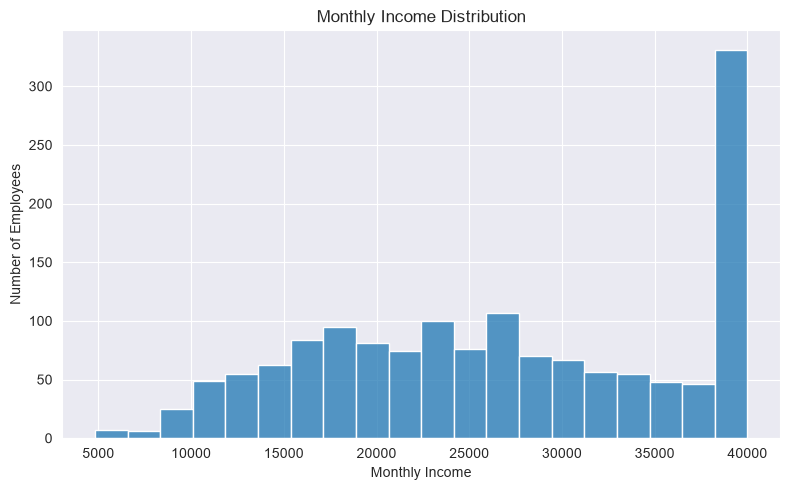

In [32]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="MonthlyIncome_EDA", bins=20)

plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

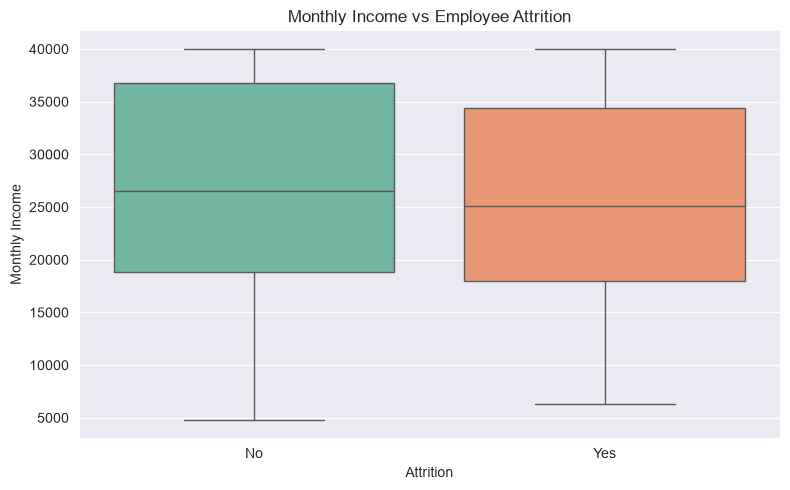

In [33]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df.dropna(subset=["Attrition"]),
    x="Attrition",
    y="MonthlyIncome_EDA",
    hue="Attrition",
    palette="Set2",
    legend=False
)

plt.title("Monthly Income vs Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")
plt.tight_layout()
plt.show()

In [34]:

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nAttrition Counts:")
print(df["Attrition"].value_counts(dropna=False))

Dataset Shape: (1500, 13)

Missing Values:
EmployeeID            0
Age                   0
Gender                0
Department            0
JobRole               0
MonthlyIncome         0
YearsAtCompany        0
JobSatisfaction       0
Attrition            22
Overtime              0
PerformanceRating     0
EducationLevel        0
MonthlyIncome_EDA     6
dtype: int64

Duplicate Rows: 0

Attrition Counts:
Attrition
No     1194
Yes     284
NaN      22
Name: count, dtype: int64


In [35]:

df_valid = df[df["Attrition"].isin(["Yes", "No"])].copy()

total_employees = len(df_valid)
employees_left = (df_valid["Attrition"] == "Yes").sum()
employees_stayed = (df_valid["Attrition"] == "No").sum()
attrition_rate = employees_left / total_employees * 100

print("FINAL EDA SUMMARY")
print("-----------------")
print("Total records:", len(df))
print("Records with known attrition:", total_employees)
print("Employees who left:", employees_left)
print("Employees who stayed:", employees_stayed)
print("Overall attrition rate:", round(attrition_rate, 2), "%")
print("Missing attrition labels:", df["Attrition"].isna().sum())
print("Flagged income values:", df["MonthlyIncome_EDA"].isna().sum())

FINAL EDA SUMMARY
-----------------
Total records: 1500
Records with known attrition: 1478
Employees who left: 284
Employees who stayed: 1194
Overall attrition rate: 19.22 %
Missing attrition labels: 22
Flagged income values: 6


## Final EDA Findings — IBM HR Analytics

1. **Overall Attrition:** 284 out of 1,478 employees with known attrition labels left the company, resulting in an attrition rate of **19.22%**.

2. **Department:** Sales has the highest department-wise attrition rate at **23.70%**, followed by Customer Support at **21.61%**.

3. **Job Role:** Sales Managers have the highest job-role attrition rate at **30.30%**.

4. **Age:** Employees under 25 have an attrition rate of **25.89%**.

5. **Job Satisfaction:** Employees with low job satisfaction have a much higher attrition rate (**33.42%**) than employees with high job satisfaction (**12.95%**).

6. **Overtime:** Employees working overtime have an attrition rate of approximately **20.43%**, compared with **18.16%** for those not working overtime.

7. **Gender:** Male employees have the highest observed attrition rate among the listed gender categories, at **21.33%**. This is a descriptive difference, not evidence that gender causes attrition.

8. **Data Quality:** The dataset contains 1,500 records, no duplicate rows, 22 missing attrition labels, and six suspicious monthly-income values flagged for analysis.

## Business Recommendations

* Investigate employee retention in the Sales and Customer Support departments.
* Review working conditions, compensation, workload, and career opportunities for Sales Managers.
* Investigate why employees with low job satisfaction are leaving at higher rates.
* Review overtime practices and employee workload.
* Develop retention strategies for younger employees.
* Validate the six suspicious income values and investigate the 22 missing attrition labels before final reporting.

## Conclusion

The exploratory data analysis identifies job satisfaction, department, job role, age group, and overtime as useful factors for further investigation into employee attrition. These patterns show associations, not proof of causation. Further statistical analysis would be needed to determine which factors independently predict attrition.
